# XGBoost collision risk model

Predicts deer and elk collisions per mile per year on one-mile highway segments from road, terrain, climate, land cover, population, and wildlife sighting features. Fit on 2015-2020 counts, scored on 2021-2025 counts, in Oregon and Idaho, within and across states.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from capstone import xgb as m
from capstone.data import RESULTS
from capstone.evaluate import evaluate

pd.set_option('display.width', 160)
BLUE, INK, INK_2, MUTED, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': 0.8, 'xtick.color': INK_2, 'ytick.color': INK_2})

TRAIN, TEST = m.windows()
STATES = ['OR', 'ID']

## Data

In [2]:
# One row per segment: the train window's count becomes the target, the test window's count is held out.
tables = {s: m.load_table(s) for s in STATES}
train = {s: m.make_fold(tables[s], TRAIN) for s in STATES}
test = {s: m.make_fold(tables[s], TEST) for s in STATES}
pd.DataFrame({s: {'segments': len(t), 'miles': round(t.length_mi.sum()), 'train collisions': train[s].deer_elk_count.sum(),
                  'test collisions': test[s].deer_elk_count.sum(), 'features': len(m.FEATURES)} for s, t in tables.items()})

,OR,ID
segments,7574,5050
miles,7338,4948
train collisions,37865,14557
test collisions,25429,8637
features,40,40


In [3]:
# Every model is scored the same way: share of test collisions on the top 1, 5, 10 percent of miles, and rank correlation.
rows = []

def score(model, trained_on, tested_on, pred):
    r = evaluate(pred, test[tested_on])
    rows.append({'model': model, 'trained_on': trained_on, 'tested_on': tested_on,
                 **{k: r[k] for k in ('capture_at_1', 'capture_at_5', 'capture_at_10', 'spearman')}})

## Reference points

In [4]:
# B0 ranks by the train window's own collision rate; random and ceiling bound what any ranking can do.
for s in STATES:
    score('B0 history rate', s, s, train[s].deer_elk_rate.to_numpy())
    score('ceiling', s, s, test[s].deer_elk_rate.to_numpy())
    rows.append({'model': 'random', 'trained_on': s, 'tested_on': s, 'capture_at_1': 0.01, 'capture_at_5': 0.05, 'capture_at_10': 0.10, 'spearman': 0.0})

## Within each state

In [5]:
# Fit on one state's covariates and score the same state's later years.
models, fit_info = {}, {}
for s in STATES:
    models[s], fit_info[s] = m.fit(train[s])
    score('XGB covariates', s, s, m.predict_rate(models[s], test[s]))
pd.DataFrame(fit_info)

,OR,ID
rounds,857.0000,867.0000
cv_poisson_nloglik,3.2319,2.6335
n_train,7574.0000,5050.0000


## Across states

In [6]:
# A model fit in one state scores the other state, then a model fit on both scores each.
for s, other in (('OR', 'ID'), ('ID', 'OR')):
    score('XGB covariates', s, other, m.predict_rate(models[s], test[other]))
pooled, info_pooled = m.fit(pd.concat([train['OR'], train['ID']], ignore_index=True))
for s in STATES:
    score('XGB covariates', 'OR+ID', s, m.predict_rate(pooled, test[s]))
info_pooled

{'rounds': 1147, 'cv_poisson_nloglik': 3.1511, 'n_train': 12624}

## Covariates plus past collisions

In [7]:
# Adds the collision rate of the five years before each window as a feature, so the model can use history like B0 does.
features_h = m.FEATURES + [m.HISTORY]
train_h = {s: m.make_fold(tables[s], TRAIN, history_window=(2010, 2014)) for s in STATES}
test_h = {s: m.make_fold(tables[s], TEST, history_window=TRAIN) for s in STATES}
models_h = {}
for s in STATES:
    models_h[s], _ = m.fit(train_h[s], features_h)
    score('XGB covariates + history', s, s, m.predict_rate(models_h[s], test_h[s], features_h))

## Results

In [8]:
results = pd.DataFrame(rows)
results.to_csv(RESULTS / 'xgb_results.csv', index=False)
order = ['random', 'XGB covariates', 'XGB covariates + history', 'B0 history rate', 'ceiling']
results['model'] = pd.Categorical(results['model'], order)
results.sort_values(['tested_on', 'model', 'trained_on']).reset_index(drop=True)

,model,trained_on,tested_on,capture_at_1,capture_at_5,capture_at_10,spearman
0,random,ID,ID,0.0100,0.0500,0.1000,0.0000
1,XGB covariates,ID,ID,0.0721,0.2302,0.3638,0.5801
2,XGB covariates,OR,ID,0.0265,0.1248,0.2218,0.4006
3,XGB covariates,OR+ID,ID,0.0701,0.2108,0.3397,0.5412
4,XGB covariates + history,ID,ID,0.0727,0.2436,0.3923,0.5771
5,B0 history rate,ID,ID,0.0760,0.2420,0.3847,0.5479
6,ceiling,ID,ID,0.1277,0.3728,0.5476,1.0000
7,random,OR,OR,0.0100,0.0500,0.1000,0.0000
8,XGB covariates,ID,OR,0.0344,0.1299,0.2165,0.4754
9,XGB covariates,OR,OR,0.0878,0.2771,0.4175,0.7426


## What the model uses

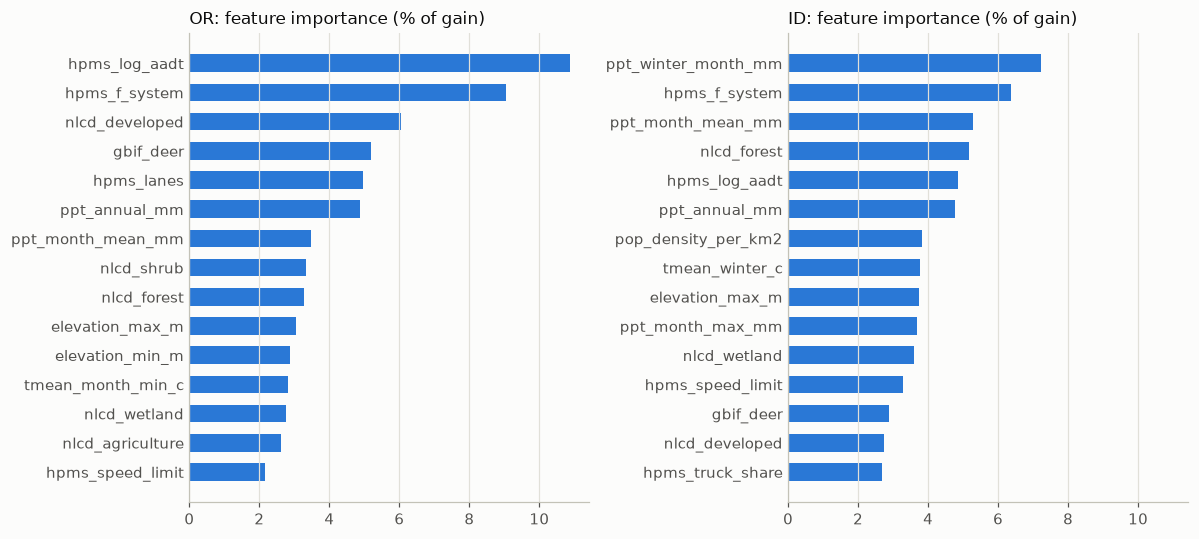

In [9]:
# Share of the model's splits explained by each feature, top 15, for the two within-state models.
imp = pd.concat([m.importance(models[s]).assign(state=s) for s in STATES])
imp.to_csv(RESULTS / 'xgb_importance.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
for ax, s in zip(axes, STATES):
    top = imp[imp.state == s].head(15).iloc[::-1]
    ax.barh(top.feature, 100 * top.share, color=BLUE, height=0.6)
    ax.set_title(f'{s}: feature importance (% of gain)', loc='left', fontsize=11)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

## Takeaways

- In Oregon, covariates alone rank nearly as well as past collisions: the top 10% of miles capture 42% of future collisions, against 43% for the history ranking and 17% for the earlier traffic-only model. Adding history on top gives the best ranking (44%, rank correlation 0.77).
- In Idaho the same holds at lower levels (36% against 38% for history), and the gap to the ceiling is wider because many Idaho reports fall on roads off the state system and reporting has shifted over time.
- A model fit in one state does not transfer: trained on Oregon and scored on Idaho (or the reverse) it captures about 22% of collisions in the top 10% of miles, better than random but far below a model fit in the state. A model fit on both states does as well within each state as the single-state models.
- The two states lean on different features: traffic, road class, and developed land in Oregon; winter precipitation, elevation, and forest cover in Idaho. Bird sightings (owls, hawks, eagles) are left out of the features: an earlier run ranked golden eagle sightings first in Oregon, but the routes dense in eagle records were mostly near-zero collision roads, so the column was marking where people record observations, not deer or elk risk. Removing the birds did not change accuracy.
- Results are in `results/xgb_results.csv` and `results/xgb_importance.csv`.